# Address-order checker · central Helsinki

Five checks that compare a city's addresses with its streets, from text to geometry:

| Check | What it flags |
|---|---|
| **text** | the street name in the address differs from the street's own name (case, hyphen, typo, a building name in the street field), or the house number carries extra text (floor, courtyard, reversed range) |
| **far** | the address sits more than 120 m from the nearest mapped part of its street |
| **dup** | the same address is tagged on separate buildings or blocks |
| **side** | an odd or even number sits on the other side from the rest of its street |
| **sequence** | a number breaks the running order along its side of the street |

Flags are things to review, not verdicts: the street line can be the wrong part as easily as the address.

**Data:** the OpenStreetMap extract of central Helsinki (April 2019) that ships with the open-source `pyrosm` library. © OpenStreetMap contributors, ODbL 1.0. It is a snapshot: many of these flags will have been fixed on OpenStreetMap since.

**Run it:** `pip install pyrosm osmium geopandas scipy matplotlib`, then run this notebook next to `address_order.py`.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import address_order as ao
plt.rcParams["figure.dpi"] = 72
pd.set_option("display.max_colwidth", 90)

T, B, S = ao.load()
print(f"{len(T):,} address tags (shops, offices and buildings with a street and house number)")
print(f"{len(B):,} building outlines, {len(S.any):,} named streets")
T.drop(columns="geometry").sample(8, random_state=1)

1,535 address tags (shops, offices and buildings with a street and house number)
486 building outlines, 100 named streets


,raw_street,raw_hn
60,Eerikinkatu,10
577,Yrjönkatu,8-10
268,Simonkatu,1
111,Unioninkatu,9
1196,Siltasaarenkatu,4
587,Keskuskatu,7
702,Vuorikatu,5
1481,Keskuskatu,1b


## 1 · Reading the address text

A house number is split into the number the checks use and anything written after it. Ranges like `4-6` are normal in Finland (one building spanning several numbers); floor and courtyard notes belong in other tags.

In [2]:
for h in ["12", "13 A", "4-6", "29-27", "13 A, 5. krs./Floor 5", "7 B, sisäpiha"]:
    print(f"{h!r:28} ->", ao.house(h))

'12'                         -> ('12', 12, '')
'13 A'                       -> ('13 A', 13, '')
'4-6'                        -> ('4-6', 4, '')
'29-27'                      -> ('29-27', 29, 'reversed range')
'13 A, 5. krs./Floor 5'      -> ('13 A', 13, 'extra text in house number')
'7 B, sisäpiha'              -> ('7 B', 7, 'extra text in house number')


The street name is matched to the street register in steps: exact name, then the part after a comma (a building name typed in front), then the same name ignoring case and hyphens, then a close spelling (similarity ≥ 0.88) **only if that street is within 120 m**. Anything that still doesn't match is left *unchecked*: its street isn't in this extract.

In [3]:
from shapely.geometry import Point
for raw in ["Kluuvinkatu", "Kaivopiha, Mannerheimintie", "Yrjö Koskisen katu", "Iso Roobertinkatu"]:
    where = T.loc[T.raw_street == raw, "geometry"].iloc[0]
    print(f"{raw!r:30} ->", ao.match(raw, where, S))

'Kluuvinkatu'                  -> ('Kluuvikatu', "likely typo (street is 'Kluuvikatu')")
'Kaivopiha, Mannerheimintie'   -> ('Mannerheimintie', 'building name in street field')
'Yrjö Koskisen katu'           -> ('Yrjö-Koskisen katu', 'spelling differs from street name (case or hyphen)')
'Iso Roobertinkatu'            -> (None, '')


## 2 · Running the checks

Tags are first collapsed into one record per address. A tag stands for the building it sits in, so twenty shops inside one shopping centre count as one place; tags of the same address on buildings more than 25 m apart are kept apart and flagged as **dup**.

**side** and **sequence** need a position along the street and a side. Each street gets one axis (the main direction of its line); an address is projected to its nearest point on the street, and the local direction of the street there tells which side it is on. Streets that bend too much for one axis are skipped.

In [4]:
A = ao.check(T, B, S)
counts = A.f.value_counts().rename("addresses (by first flag)")
print(f"{len(A)} addresses, {A.street.notna().sum()} checked against a street, {(~A.f.isin(['ok','unchecked'])).sum()} flagged")
counts.to_frame()

580 addresses, 572 checked against a street, 43 flagged


,addresses (by first flag)
f,
ok,529
text,22
dup,12
unchecked,8
sequence,3
side,3
far,3


In [5]:
flagged = A[~A.f.isin(["ok", "unchecked"])].copy()
flagged["address"] = flagged.written + " " + flagged.hn
flagged["why"] = flagged.fl.map(lambda fl: " | ".join(f"{k}: {w}" for k, w in fl))
flagged.sort_values(["f", "address"])[["f", "address", "why"]].reset_index(drop=True)

,f,address,why
0,dup,Asema-aukio 2,text: likely typo (street is 'Asema-aukio'); spelling differs from street name (case o...
1,dup,Elielinaukio 2,dup: tagged on 2 separate buildings or blocks
2,dup,Keskuskatu 5,dup: tagged on 2 separate buildings or blocks
3,dup,Kirkkokatu 18,dup: tagged on 2 separate buildings or blocks
4,dup,Mannerheimintie 1,dup: tagged on 2 separate buildings or blocks
5,dup,Mannerheimintie 14-20,dup: tagged on 3 separate buildings or blocks
6,dup,Mannerheimintie 3,text: building name in street field | dup: tagged on 2 separate buildings or blocks
7,dup,Postikatu 1,dup: tagged on 2 separate buildings or blocks
8,dup,Simonkatu 12,dup: tagged on 2 separate buildings or blocks
9,dup,Unioninkatu 29,dup: tagged on 2 separate buildings or blocks


## 3 · Where they are

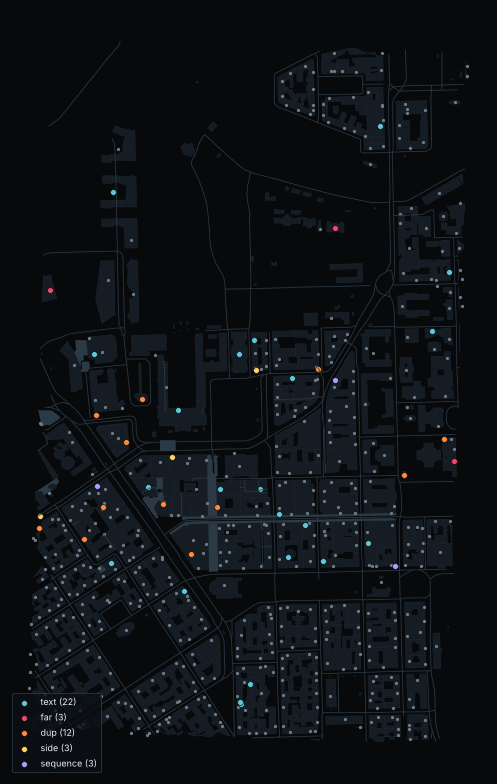

In [6]:
COL = {"text": "#5ec8d8", "far": "#ef476f", "dup": "#ff8a3d", "side": "#ffd166", "sequence": "#b39dfa"}
G = A.to_crs(3067)
fig, ax = plt.subplots(figsize=(9, 11), facecolor="#07090b")
ax.set_facecolor("#07090b")
B.plot(ax=ax, color="#151c23", edgecolor="#1f2a33", linewidth=.4)
import geopandas as gpd
gpd.GeoSeries(list(S.any.values()), crs=3067).plot(ax=ax, color="#2c3a45", linewidth=.8)
G[G.f == "ok"].plot(ax=ax, color="#6d7c86", markersize=5)
for k, c in COL.items():
    g = G[G.f == k]
    if len(g): g.plot(ax=ax, color=c, markersize=34, edgecolor="#07090b", linewidth=.6, label=f"{k} ({len(g)})")
ax.legend(loc="lower left", facecolor="#0c1014", edgecolor="#2c3a45", labelcolor="#e6ecef", fontsize=9)
ax.set_axis_off(); plt.tight_layout()

## 4 · Does it catch what it should? Planted errors

Clean addresses are broken on purpose, then the checks run again on the broken copy. Each round plants 10 errors of each kind:

* **text**: one letter dropped from the street name
* **far**: the address moved 250 m in a random direction
* **dup**: the address copied onto another building at least 150 m away
* **side**: the address mirrored across its street
* **sequence**: two numbers on the same side of a street, at least 40 m apart, swapped

text, far and dup are sanity checks: the planted errors are large. side and sequence are the real test. Errors are only planted where a check can apply (for side, streets with at least 4 other numbers).

In [7]:
rows = []
for seed in range(1, 6):
    T2, truth = ao.plant(T, A, S, n=10, seed=seed)
    for k, v in ao.score(ao.check(T2, B, S), truth).items():
        rows.append({"round": seed, "check": k, **v})
test = pd.DataFrame(rows).groupby("check", sort=False)[["planted", "caught"]].sum()
test["share"] = (test.caught / test.planted).map("{:.0%}".format)
test

,planted,caught,share
check,,,
text,50,50,100%
far,50,50,100%
dup,50,50,100%
side,50,48,96%
sequence,50,50,100%


In [8]:
cov = {"side": A.side_ok.sum() / A.street.notna().sum(), "sequence": A.seq_ok.sum() / A.street.notna().sum()}
print({k: f"{v:.0%} of checked addresses" for k, v in cov.items()})

{'side': '75% of checked addresses', 'sequence': '64% of checked addresses'}


## 5 · Limits

* **Coverage.** side only applies on streets with enough numbers to say which side is odd; sequence only on runs of at least four numbers of one parity on one side. Ranges (`4-6`) are left out of sequence because they overlap their own numbers.
* **Thresholds are judgement calls:** 120 m for *far*, 25 m between buildings for *dup*, 15 m outside its stretch for *sequence*, 0.88 name similarity. The planted typos are single dropped letters; a heavier misspelling falls below 0.88 and is left *unchecked* instead.
* **Position comes from shop nodes and building centres**, not entrances, so a corner building can sit a little out of order. That is what the 15 m tolerance absorbs.
* **One snapshot (April 2019).** The flags say nothing about OpenStreetMap today.

## 6 · Export for the map on the site

In [9]:
s = ao.export(A, S, "../data/lab/address-order", {"tags": int(A.tags.sum()), "planted_test": {k: {"planted": int(r.planted), "caught": int(r.caught)} for k, r in test.iterrows()}})
ao.export_base(B, "../data/lab/address-order")
print(json.dumps({k: s[k] for k in ["tags", "addresses", "checked", "flagged", "primary", "coverage"]}, indent=1))

{
 "tags": 1535,
 "addresses": 580,
 "checked": 572,
 "flagged": 43,
 "primary": {
  "text": 22,
  "far": 3,
  "dup": 12,
  "side": 3,
  "sequence": 3,
  "ok": 529,
  "unchecked": 8
 },
 "coverage": {
  "side": 0.75,
  "sequence": 0.638
 }
}
